In [22]:
import pandas as pd
import os

# os.chdir(os.path.dirname(os.path.abspath(__file__)))

In [23]:
fisheries = pd.read_csv('data/FL_Fisheries_Independent_Monitoring_Inshore_Stratified-Random_Sampling_Records.csv')

In [24]:
fisheries.columns

Index(['X', 'Y', 'OBJECTID', 'Reference', 'Sampling_Date', 'Latitude',
       'Longitude', 'Gear', 'Scientificname', 'Commonname', 'TotalNum',
       'avg_size', 'min_size', 'max_size', 'Shape', 'Export_Date'],
      dtype='str')

In [25]:
fisheries.shape

(1765226, 16)

In [77]:
tampa_bay = fisheries[fisheries['Reference'].str.contains("TBM")].reset_index()
tampa_bay = tampa_bay[['Reference', 'Sampling_Date', 'Gear', 'Commonname', 'Scientificname', 'TotalNum', 'avg_size', 'min_size', 'max_size']]

In [78]:
fisheries['Reference'].str[0:3].unique()

<StringArray>
['ANM', 'APM', 'BBM', 'CHM', 'CHX', 'CKM', 'CKX', 'CRM', 'CZM', 'EBM', 'EVM',
 'FBM', 'FWM', 'FWX', 'GLM', 'HIM', 'HSM', 'IRM', 'IRX', 'JXM', 'KYM', 'LBM',
 'PBM', 'SAM', 'SBM', 'SJM', 'TBD', 'TBM', 'TBX', 'TQM', 'TQX', 'WWM']
Length: 32, dtype: str

In [79]:
tampa_bay['Commonname'].unique()

<StringArray>
[       'Striped Burrfish',              'Naked Goby',
       'Atlantic Stingray',        'Leopard Searobin',
        'Scrawled Cowfish',             'Bay Anchovy',
        'Hardhead Catfish',               'Blue Crab',
       'Tidewater Mojarra',          'Lined Seahorse',
 ...
               'Flounders', 'Atlantic Calico Scallop',
         'Barred Searobin',   'Foureye Butterflyfish',
              'Filefishes',            'Nile Tilapia',
         'Reef Silverside',            'Reef Croaker',
              'filefishes',          'requiem sharks']
Length: 383, dtype: str

In [80]:
tampa_bay[tampa_bay['Commonname'] == 'Reef Croaker']['Sampling_Date'].unique()

<StringArray>
['2023/07/10 04:00:00+00']
Length: 1, dtype: str

In [177]:
counts = tampa_bay['Commonname'].value_counts()
# keep = counts[counts > 30].index

# filtered = tampa_bay[tampa_bay['Commonname'].isin(keep)]
filtered = tampa_bay
filtered

,Reference,Sampling_Date,Gear,Commonname,Scientificname,TotalNum,avg_size,min_size,max_size
0,TBM1996011601,1996-01-16 05:00:00+00:00,300,Striped Burrfish,Chilomycterus schoepfii,1,148.0,148.0,148.0
1,TBM1996011601,1996-01-16 05:00:00+00:00,300,Naked Goby,Gobiosoma bosc,3,31.0,29.0,34.0
2,TBM1996011601,1996-01-16 05:00:00+00:00,300,Atlantic Stingray,Hypanus sabinus,1,247.0,247.0,247.0
3,TBM1996011601,1996-01-16 05:00:00+00:00,300,Leopard Searobin,Prionotus scitulus,20,49.0,38.0,90.0
4,TBM1996011602,1996-01-16 05:00:00+00:00,300,Scrawled Cowfish,Acanthostracion quadricornis,5,68.0,19.0,139.0
...,...,...,...,...,...,...,...,...,...
409776,TBM2023123318,2023-12-13 05:00:00+00:00,5,Sheepshead Minnow,Cyprinodon variegatus,8,15.0,12.0,20.0
409777,TBM2023123318,2023-12-13 05:00:00+00:00,5,Silver Jenny,Eucinostomus gula,1,48.0,48.0,48.0
409778,TBM2023123318,2023-12-13 05:00:00+00:00,5,Eucinostomus,Eucinostomus spp.,23,26.0,23.0,31.0
409779,TBM2023123318,2023-12-13 05:00:00+00:00,5,Goldspotted Killifish,Floridichthys carpio,11,36.0,19.0,46.0


In [178]:
filtered['Sampling_Date'] = pd.to_datetime(filtered['Sampling_Date'])

In [179]:
import matplotlib.pyplot as plt

In [180]:
filtered['Commonname'].unique()

<StringArray>
[       'Striped Burrfish',              'Naked Goby',
       'Atlantic Stingray',        'Leopard Searobin',
        'Scrawled Cowfish',             'Bay Anchovy',
        'Hardhead Catfish',               'Blue Crab',
       'Tidewater Mojarra',          'Lined Seahorse',
 ...
               'Flounders', 'Atlantic Calico Scallop',
         'Barred Searobin',   'Foureye Butterflyfish',
              'Filefishes',            'Nile Tilapia',
         'Reef Silverside',            'Reef Croaker',
              'filefishes',          'requiem sharks']
Length: 383, dtype: str

In [181]:
filtered = filtered.set_index('Sampling_Date').sort_index()

In [182]:
yearly_avg = filtered.groupby(['Scientificname', 'Commonname']).resample('YE').agg({
    'TotalNum': 'mean',
    'avg_size': 'mean',
    'min_size': 'mean',
    'max_size': 'mean',
}).reset_index().fillna(0)
yearly_avg

,Scientificname,Commonname,Sampling_Date,TotalNum,avg_size,min_size,max_size
0,Acanthostracion quadricornis,Scrawled Cowfish,1996-12-31 00:00:00+00:00,2.000000,109.483146,99.887640,120.696629
1,Acanthostracion quadricornis,Scrawled Cowfish,1997-12-31 00:00:00+00:00,2.307018,110.333333,98.877193,124.043860
2,Acanthostracion quadricornis,Scrawled Cowfish,1998-12-31 00:00:00+00:00,2.116279,145.627907,133.348837,161.418605
3,Acanthostracion quadricornis,Scrawled Cowfish,1999-12-31 00:00:00+00:00,1.895833,127.791667,121.604167,134.500000
4,Acanthostracion quadricornis,Scrawled Cowfish,2000-12-31 00:00:00+00:00,2.744186,127.534884,112.023256,146.488372
...,...,...,...,...,...,...,...
6618,Xiphophorus spp.,livebearers,2017-12-31 00:00:00+00:00,0.000000,0.000000,0.000000,0.000000
6619,Xiphophorus spp.,livebearers,2018-12-31 00:00:00+00:00,0.000000,0.000000,0.000000,0.000000
6620,Xiphophorus spp.,livebearers,2019-12-31 00:00:00+00:00,0.000000,0.000000,0.000000,0.000000
6621,Xiphophorus spp.,livebearers,2020-12-31 00:00:00+00:00,0.000000,0.000000,0.000000,0.000000


In [183]:
yearly_avg['Year'] = yearly_avg['Sampling_Date'].dt.year

In [184]:
yearly_avg['Scientificname'].value_counts()

Scientificname
Acanthostracion quadricornis    28
Achirus lineatus                28
Aluterus schoepfii              28
Anarchopterus criniger          28
Anchoa hepsetus                 28
                                ..
Tilapia spp.                     1
Tozeuma spp.                     1
Trachinotus spp.                 1
Trichromis salvini               1
Tylosurus spp.                   1
Name: count, Length: 401, dtype: int64

In [187]:
yearly_avg[yearly_avg['Scientificname'] == 'Acanthostracion quadricornis']['Commonname'].unique()

<StringArray>
['Scrawled Cowfish']
Length: 1, dtype: str

In [194]:
yearly_avg[['Scientificname', 'Commonname']].drop_duplicates()

,Scientificname,Commonname
0,Acanthostracion quadricornis,Scrawled Cowfish
28,Achiridae spp.,American Soles
52,Achirus lineatus,Lined Sole
80,Aetobatus narinari,Spotted Eagle Ray
106,Albula goreensis,Senegalese Bonefish
...,...,...
6549,Tylosurus crocodilus,Houndfish
6570,Tylosurus spp.,needlefishes
6571,Unidentified species,Unidentified species
6575,Urophycis floridana,Southern Hake


In [203]:
yearly_avg[['Scientificname', 'Commonname']].value_counts()

Scientificname                Commonname         
Acanthostracion quadricornis  Scrawled Cowfish       28
Achirus lineatus              Lined Sole             28
Aluterus schoepfii            Orange Filefish        28
Anarchopterus criniger        Fringed Pipefish       28
Anchoa hepsetus               Striped Anchovy        28
                                                     ..
Tilapia spp.                  Tilapias                1
Tozeuma spp.                  Arrow Shrimp            1
Trachinotus spp.              jacks                   1
Trichromis salvini            Yellowbelly Cichlid     1
Tylosurus spp.                needlefishes            1
Name: count, Length: 401, dtype: int64

In [202]:
counts = yearly_avg.groupby(['Scientificname','Commonname'])['Scientificname'].transform('size')
counts

0       28
1       28
2       28
3       28
4       28
        ..
6618    20
6619    20
6620    20
6621    20
6622    20
Name: Scientificname, Length: 6623, dtype: int64

In [204]:
filtered_fish = yearly_avg[counts > 10]

In [205]:
filtered_fish['Scientificname'].value_counts()

Scientificname
Acanthostracion quadricornis    28
Achirus lineatus                28
Aluterus schoepfii              28
Anarchopterus criniger          28
Anchoa hepsetus                 28
                                ..
Chalinops pauciradiatus         11
Elopiformes spp.                11
Notropis spp.                   11
Ophidion holbrookii             11
Periclimenes americanus         11
Name: count, Length: 258, dtype: int64

In [206]:
yearly_avg[yearly_avg['Scientificname'] == 'Acanthostracion quadricornis'].shape

(28, 8)

In [207]:
fish_specific = yearly_avg[yearly_avg['Scientificname'] == 'Acanthostracion quadricornis']
fish_specific

,Scientificname,Commonname,Sampling_Date,TotalNum,avg_size,min_size,max_size,Year
0,Acanthostracion quadricornis,Scrawled Cowfish,1996-12-31 00:00:00+00:00,2.000000,109.483146,99.887640,120.696629,1996
1,Acanthostracion quadricornis,Scrawled Cowfish,1997-12-31 00:00:00+00:00,2.307018,110.333333,98.877193,124.043860,1997
2,Acanthostracion quadricornis,Scrawled Cowfish,1998-12-31 00:00:00+00:00,2.116279,145.627907,133.348837,161.418605,1998
3,Acanthostracion quadricornis,Scrawled Cowfish,1999-12-31 00:00:00+00:00,1.895833,127.791667,121.604167,134.500000,1999
4,Acanthostracion quadricornis,Scrawled Cowfish,2000-12-31 00:00:00+00:00,2.744186,127.534884,112.023256,146.488372,2000
5,Acanthostracion quadricornis,Scrawled Cowfish,2001-12-31 00:00:00+00:00,2.403509,133.105263,125.245614,141.210526,2001
6,Acanthostracion quadricornis,Scrawled Cowfish,2002-12-31 00:00:00+00:00,3.421053,96.946429,78.928571,120.107143,2002
7,Acanthostracion quadricornis,Scrawled Cowfish,2003-12-31 00:00:00+00:00,3.524390,115.560976,106.182927,126.036585,2003
8,Acanthostracion quadricornis,Scrawled Cowfish,2004-12-31 00:00:00+00:00,2.079365,129.285714,119.984127,140.158730,2004
9,Acanthostracion quadricornis,Scrawled Cowfish,2005-12-31 00:00:00+00:00,1.718310,126.859155,120.704225,133.408451,2005


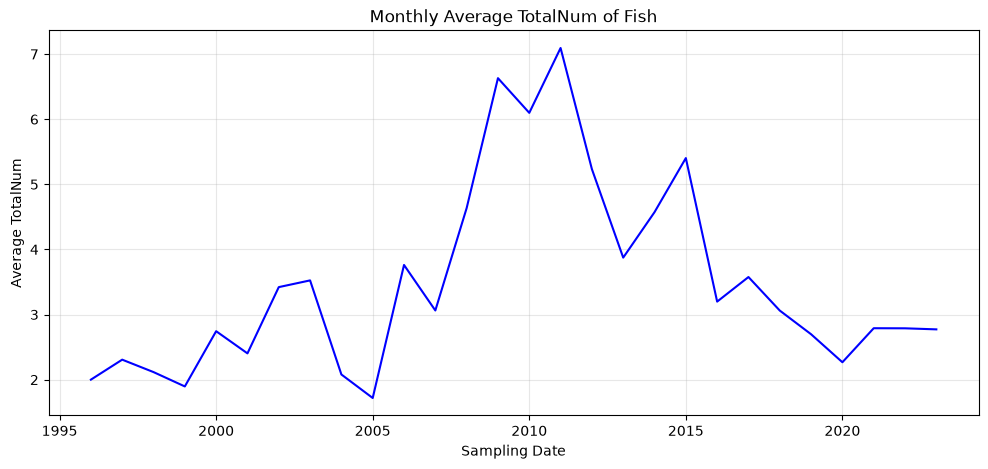

In [208]:
plt.figure(figsize=(12, 5))
plt.plot(fish_specific['Year'], fish_specific['TotalNum'], color='blue', linewidth=1.5)
plt.title('Monthly Average TotalNum of Fish')
plt.xlabel('Sampling Date')
plt.ylabel('Average TotalNum')
plt.grid(True, alpha=0.3)
plt.show()

In [20]:
seagrass = pd.read_csv('data/sgsegest.csv')
seagrass

,segment,acres,year
0,Boca Ciega Bay,6258.932576,1988
1,Hillsborough Bay,6.770810,1988
2,Lower Tampa Bay,5523.984360,1988
3,Manatee River,347.249089,1988
4,Middle Tampa Bay,5195.761701,1988
...,...,...,...
121,Terra Ceia Bay,993.461512,2024
122,Old Tampa Bay,3857.513304,2024
123,Manatee River,463.093884,2024
124,Lower Tampa Bay,8035.856071,2024


In [21]:
seagrass['year'].dtype

dtype('int64')

In [22]:
yearly_acrage = seagrass.groupby('year')[['acres']].sum().reset_index()

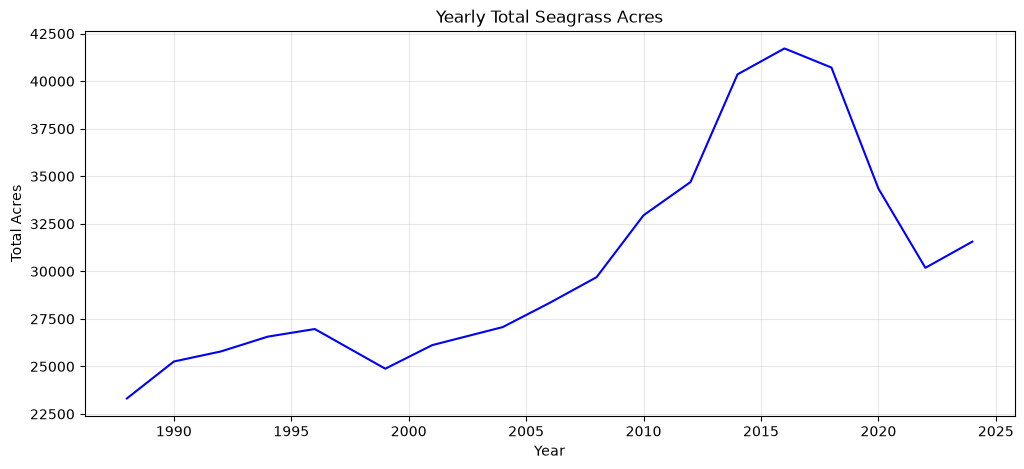

In [23]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_acrage['year'], yearly_acrage['acres'], color='blue', linewidth=1.5)
plt.title('Yearly Total Seagrass Acres')
plt.xlabel('Year')
plt.ylabel('Total Acres')
plt.grid(True, alpha=0.3)
plt.show()

In [209]:
water_quality = pd.read_csv('data/clean_water_quality.csv')

In [210]:
water_quality['SampleDate'].dtype

<StringDtype(storage='python', na_value=nan)>

In [211]:
water_quality['SampleDate'] = pd.to_datetime(water_quality['SampleDate'])

In [212]:
water_quality['WaterBodyName'].unique()

<StringArray>
[           'Hayes Bayou',         'Boca Ciega Bay',      'Clearwater Harbor',
       'Hillsborough Bay', 'Long Bayou/Cross Bayou',        'Lower Tampa Bay']
Length: 6, dtype: str

In [49]:
cleaned_water_quality = water_quality.dropna(axis=1, thresh=len(water_quality)*0.2)

In [50]:
cleaned_water_quality.columns

Index(['WBodyID', 'WaterBodyName', 'StationID', 'StationName',
       'Actual_StationID', 'Actual_Latitude', 'Actual_Longitude', 'DEP_WBID',
       'SampleDate', 'ActivityDepth (m)', 'Salinity_ppt', 'TempW_F', 'pH'],
      dtype='str')

In [55]:
water_quality.columns

Index(['WBodyID', 'WaterBodyName', 'StationID', 'StationName',
       'Actual_StationID', 'Actual_Latitude', 'Actual_Longitude', 'DEP_WBID',
       'SampleDate', 'ActivityDepth (m)', 'Salinity_ppt', 'TempW_F', 'pH',
       'Ca_mgl', 'Pb_ugl', 'Na_mgl', 'NH3_N_mgl', 'TempA_F', 'NO3_mgl',
       'NO2_mgl', 'SO4_mgl', 'NH4_mgl'],
      dtype='str')

In [225]:
water_quality['RegionName'] = 'Tampa Bay'

In [226]:
data = water_quality.set_index('SampleDate').sort_index()
yearly_water_avg = data.groupby('RegionName').resample('YE').agg({
    'NH3_N_mgl': 'mean',
    'NO3_mgl': 'mean',
    'TempW_F': 'mean',
    'pH': 'mean',
    'Salinity_ppt': 'mean',
}).reset_index()
yearly_water_avg['year'] = yearly_water_avg['SampleDate'].dt.year
yearly_water_avg

,RegionName,SampleDate,NH3_N_mgl,NO3_mgl,TempW_F,pH,Salinity_ppt,year
0,Tampa Bay,1976-12-31,NaN,0.278519,60.093846,8.198571,26.342623,1976
1,Tampa Bay,1977-12-31,0.360395,0.056863,73.379940,8.425301,27.531780,1977
2,Tampa Bay,1978-12-31,0.114695,0.065605,75.242432,8.469104,22.458519,1978
3,Tampa Bay,1979-12-31,0.074568,0.056203,74.600863,8.413824,21.389318,1979
4,Tampa Bay,1980-12-31,0.146320,0.073818,75.461753,8.313701,23.711917,1980
5,Tampa Bay,1981-12-31,0.183517,0.061788,75.961722,8.397333,26.009045,1981
6,Tampa Bay,1982-12-31,0.111260,0.061972,73.843025,8.363684,27.493316,1982
7,Tampa Bay,1983-12-31,0.131935,0.113111,75.151619,7.788549,24.302655,1983
8,Tampa Bay,1984-12-31,0.093847,0.060571,73.913204,8.001464,27.271116,1984
9,Tampa Bay,1985-12-31,0.134333,0.025545,76.465068,7.991044,28.646943,1985


In [228]:
combine_water = yearly_water_avg.groupby('year')[['NH3_N_mgl', 'NO3_mgl', 'TempW_F', 'pH', 'Salinity_ppt']].mean().reset_index()

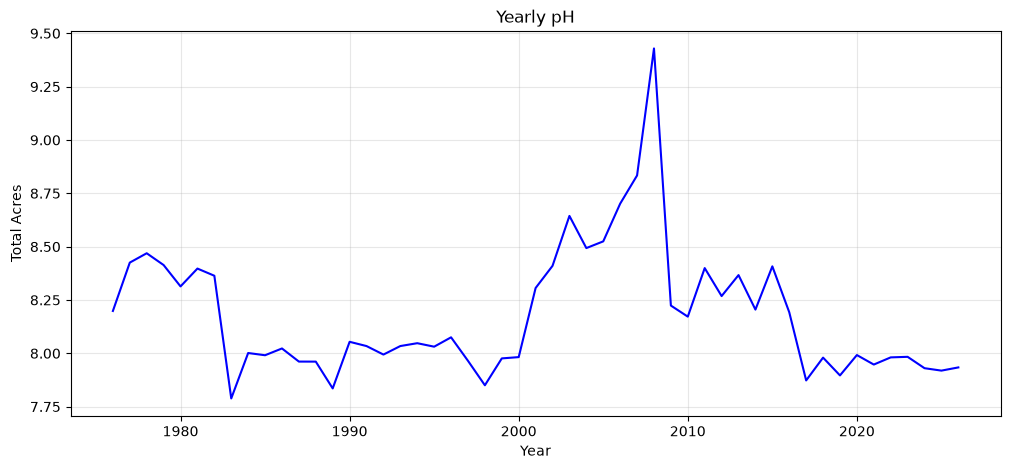

In [229]:
plt.figure(figsize=(12, 5))
plt.plot(combine_water['year'], combine_water['pH'], color='blue', linewidth=1.5)
plt.title('Yearly pH')
plt.xlabel('Year')
plt.ylabel('Total Acres')
plt.grid(True, alpha=0.3)
plt.show()

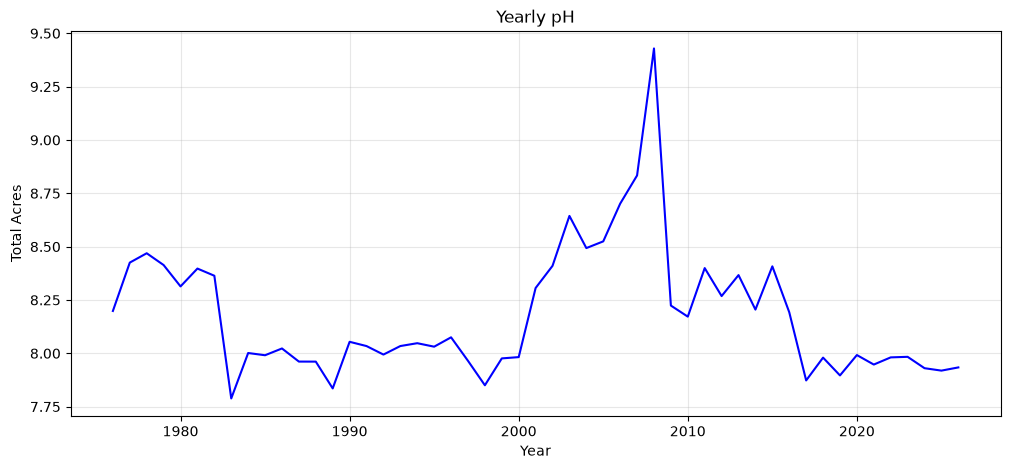

In [227]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_water_avg['year'], yearly_water_avg['pH'], color='blue', linewidth=1.5)
plt.title('Yearly pH')
plt.xlabel('Year')
plt.ylabel('Total Acres')
plt.grid(True, alpha=0.3)
plt.show()

In [79]:
revenue = pd.read_csv('data/Tampa_Bay_Revenue.csv')
revenue

,Year,Net_Investment,Port_Usage_fees,Land_lease,dockage_Cargo,dockage_Cruise,dockage_Other,wharfage_Cargo,wharfage_Cruise,wharfage_Other,Dry_Cargo,Liquid_Cargo,General_Cargo,Cruise_Passenger_Count,Cruise_Revenue
0,2016,581841,36793,11752,5813,1032.0,659,9791,6371.0,8706,4458,8650,1033,813800.0,9879538.0
1,2017,594645,39916,13058,6926,1203.0,229,10561,8041.0,8231,4988,8625,1368,960901.0,11823004.0
2,2018,611124,43603,13058,7402,1277.0,463,11991,8868.0,8356,5488,9329,1389,1043329.0,12876002.0
3,2019,641903,46206,18040,7270,1340.0,845,11521,10178.0,9942,5337,9591,1315,1149289.0,13918893.0
4,2020,645586,37480,18090,7313,668.0,733,11892,4735.0,8767,6193,8665,1319,507920.0,6398069.0
5,2021,661548,35037,23288,8460,NaN,751,13026,NaN,9747,6385,9196,1550,NaN,NaN
6,2022,680034,46100,23605,10262,630.0,1213,12794,4411.0,11274,5415,8849,1890,418156.0,6253298.0
7,2023,705783,59492,25662,11446,1144.0,2279,14266,10791.0,10853,5613,9891,1821,1124057.0,14999919.0
8,2024,730710,60856,26291,11825,1173.0,1394,14426,12066.0,10161,6051,9680,1962,1210292.0,16809968.0
9,2025,790607,70828,31044,11234,1488.0,1742,13734,17744.0,12275,5009,10762,1672,1660315.0,24797103.0


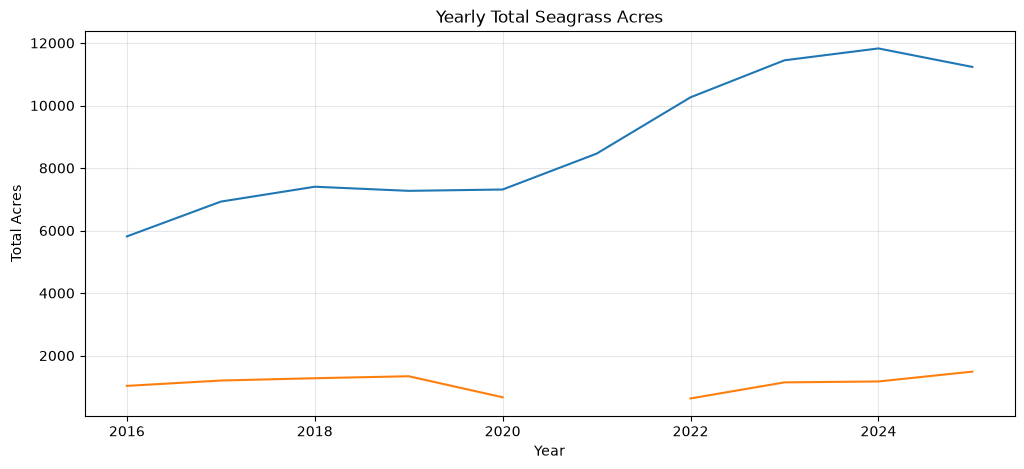

In [82]:
plt.figure(figsize=(12, 5))
plt.plot(revenue['Year'], revenue['dockage_Cargo'])
plt.plot(revenue['Year'], revenue['dockage_Cruise'])
plt.title('Yearly Total Seagrass Acres')
plt.xlabel('Year')
plt.ylabel('Total Acres')
plt.grid(True, alpha=0.3)
plt.show()